# Q1: How do post format and content category relate to reach, engagement and follower growth?

In [1]:
import pandas as pd

clean_df = pd.read_csv("instagram_analytics_cleaned.csv")

### Focus on "reach, engagement and follower growth"

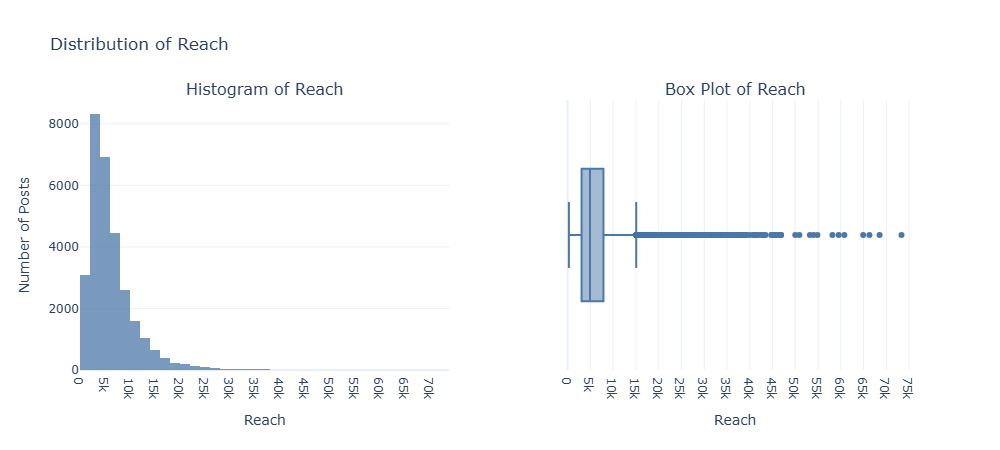

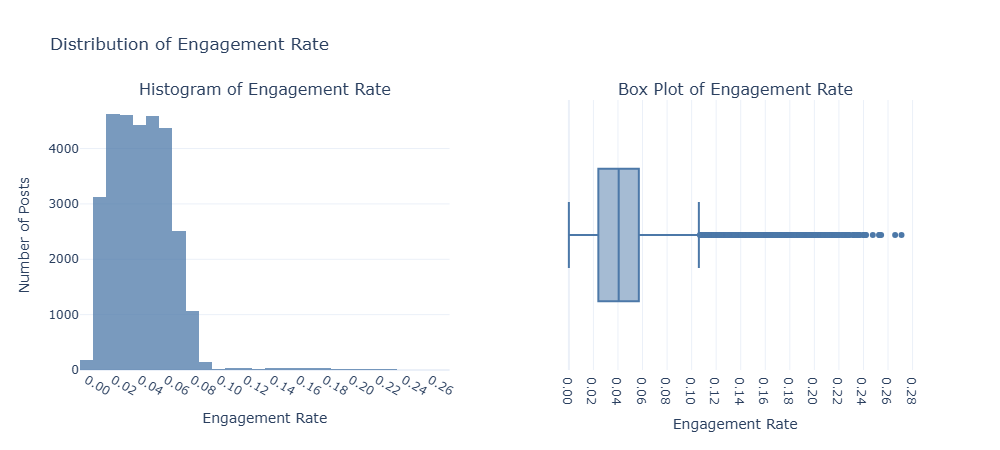

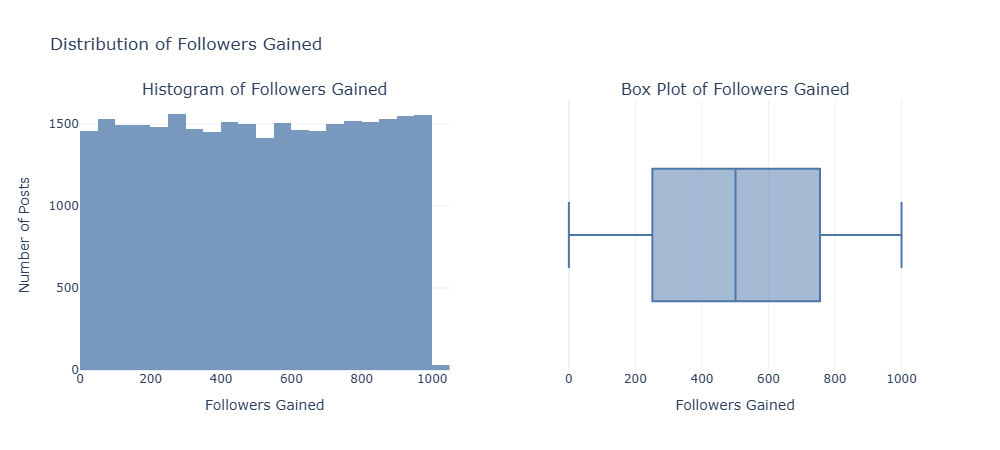

In [2]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


eda_variables = {
    "reach": {
        "title": "Reach",
        "x_title": "Reach"
    },

    "engagement_rate": {
        "title": "Engagement Rate",
        "x_title": "Engagement Rate"
    },

    "followers_gained": {
        "title": "Followers Gained",
        "x_title": "Followers Gained"
    }
}


for col, info in eda_variables.items():

    data = clean_df[col].dropna()

    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=(
            f"Histogram of {info['title']}",
            f"Box Plot of {info['title']}"
        ),
        horizontal_spacing=0.12
    )

    # -------------------------
    # Histogram
    # -------------------------

    fig.add_trace(
        go.Histogram(
            x=data,
            nbinsx=50,
            marker_color="#4C78A8",
            opacity=0.75,
            showlegend=False
        ),
        row=1,
        col=1
    )


    # -------------------------
    # Box Plot
    # -------------------------

    fig.add_trace(
        go.Box(
            x=data,
            boxpoints="outliers",
            marker_color="#4C78A8",
            line_color="#4C78A8",
            showlegend=False
        ),
        row=1,
        col=2
    )


    # -------------------------
    # Axis labels
    # -------------------------

    fig.update_xaxes(
        title_text=info["x_title"],
        row=1,
        col=1
    )

    fig.update_yaxes(
        title_text="Number of Posts",
        row=1,
        col=1
    )

    fig.update_xaxes(
        title_text=info["x_title"],
        row=1,
        col=2
    )

    # Box plot does not need a numerical y-axis
    fig.update_yaxes(
        showticklabels=False,
        title_text="",
        row=1,
        col=2
    )

    if col == "reach":

        fig.update_xaxes(
            tick0=0,
            dtick=5000,
            row=1,
            col=1
        )

        fig.update_xaxes(
            tick0=0,
            dtick=5000,
            row=1,
            col=2
        )

    if col == "engagement_rate":

        fig.update_xaxes(
            tick0=0,
            dtick=0.02,
            tickformat=".2f",
            row=1,
            col=1
        )

        fig.update_xaxes(
            tick0=0,
            dtick=0.02,
            tickformat=".2f",
            row=1,
            col=2
        )

    fig.update_layout(
        title=f"Distribution of {info['title']}",
        height=450,
        width=1000,
        showlegend=False,
        template="plotly_white"

        
    )

    fig.show(renderer="png")

### Group by content_category & media_type

In [3]:
sample_count = (
    clean_df
    .groupby(
        ["content_category", "media_type"],
        observed=True
    )
    .size()
    .reset_index(name="n_posts")
)

# Total number of posts within each content category
sample_count["category_total"] = (
    sample_count
    .groupby("content_category")["n_posts"]
    .transform("sum")
)

# Percentage within content category
sample_count["percentage"] = (
    sample_count["n_posts"]
    / sample_count["category_total"]
    * 100
)

sample_count["percentage_label"] = (
    sample_count["percentage"]
    .map(lambda x: f"{x:.1f}%")
)

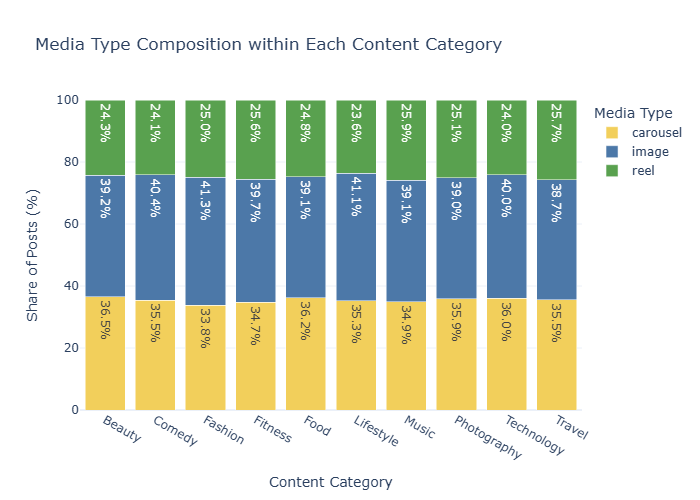

In [4]:
import plotly.express as px

media_colors = {
    "image": "#4C78A8",
    "carousel": "#F2CF5B",
    "reel": "#59A14F"
}

fig = px.bar(
    sample_count,
    x="content_category",
    y="percentage",
    color="media_type",
    text="percentage_label",
    custom_data=["n_posts"],
    color_discrete_map=media_colors,
    title="Media Type Composition within Each Content Category"
)

fig.update_traces(
    textposition="inside",
    hovertemplate=(
        "Content Category: %{x}<br>"
        "Share: %{y:.1f}%<br>"
        "Number of Posts: %{customdata[0]}"
        "<extra></extra>"
    )
)

fig.update_layout(
    barmode="stack",
    xaxis_title="Content Category",
    yaxis_title="Share of Posts (%)",
    yaxis=dict(range=[0, 100]),
    legend_title="Media Type",
    template="plotly_white"
)

fig.show(renderer="png")

The media-type composition is relatively stable across content categories. 

Images account for roughly 40% of posts, Carousels around 35%, and Reels around 25%. 

Comparisons across media types are not driven by a severe category-specific sample imbalance.

## Base metrics

### Reach Efficiency : 相對帳號本身規模，這篇貼文觸及能力如何？

In [5]:
analysis_df = clean_df.copy()

analysis_df["reach_rate"] = (
    analysis_df["reach"]
    / analysis_df["follower_count"]
)

### Engagement Efficiency : 每 1,000 個被觸及的人，產生多少次 interaction。

In [6]:
analysis_df["total_interactions"] = (
    analysis_df["likes"]
    + analysis_df["comments"]
    + analysis_df["shares"]
    + analysis_df["saves"]
)

analysis_df["interactions_per_1000_reach"] = (
    analysis_df["total_interactions"]
    / analysis_df["reach"]
    * 1000
)

### Follower Conversion : 每觸及 1,000 個人，可以轉換多少新 follower？

In [7]:
analysis_df["followers_per_1000_reach"] = (
    analysis_df["followers_gained"]
    / analysis_df["reach"]
    * 1000
)

### Group by (overall analysis)

reach、likes、shares 等資料明顯右偏，所以用median作為指標

In [8]:
format_performance = (
    analysis_df
    .groupby(
        ["content_category", "media_type"],
        observed=True
    )
    .agg(
        n_posts=(
            "post_id",
            "count"
        ),

        median_reach_rate=(
            "reach_rate",
            "median"
        ),

        median_interaction_efficiency=(
            "interactions_per_1000_reach",
            "median"
        ),

        median_follower_conversion=(
            "followers_per_1000_reach",
            "median"
        )
    )
    .reset_index()
)

format_performance

,content_category,media_type,n_posts,median_reach_rate,median_interaction_efficiency,median_follower_conversion
0,Beauty,carousel,1078,0.596891,51.577057,83.171563
1,Beauty,image,1158,0.583072,54.769253,92.974035
2,Beauty,reel,717,0.538257,57.577763,88.817825
3,Comedy,carousel,1046,0.583349,56.037383,91.685907
4,Comedy,image,1192,0.564773,54.856121,88.335104
5,Comedy,reel,712,0.593836,54.804709,90.907905
6,Fashion,carousel,1025,0.559578,53.670437,85.916740
7,Fashion,image,1252,0.571988,55.979590,88.992192
8,Fashion,reel,757,0.540017,57.757397,92.004264
9,Fitness,carousel,1042,0.574203,54.209284,90.812400


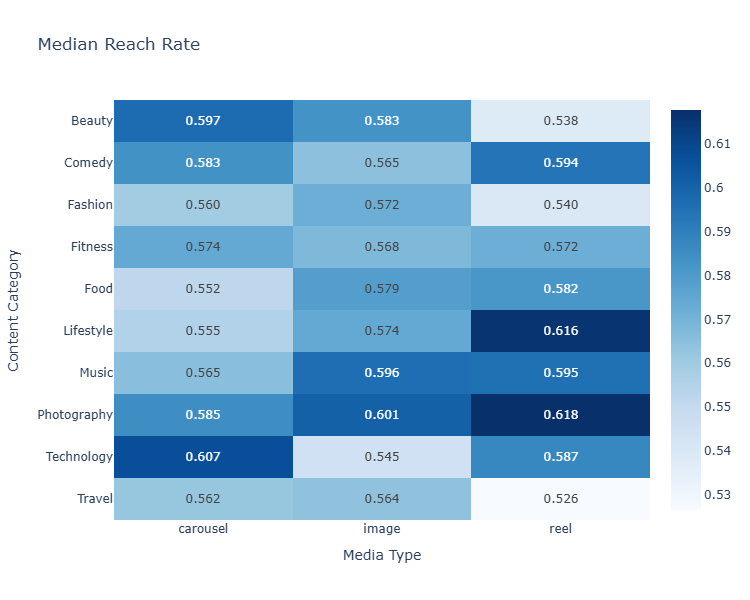

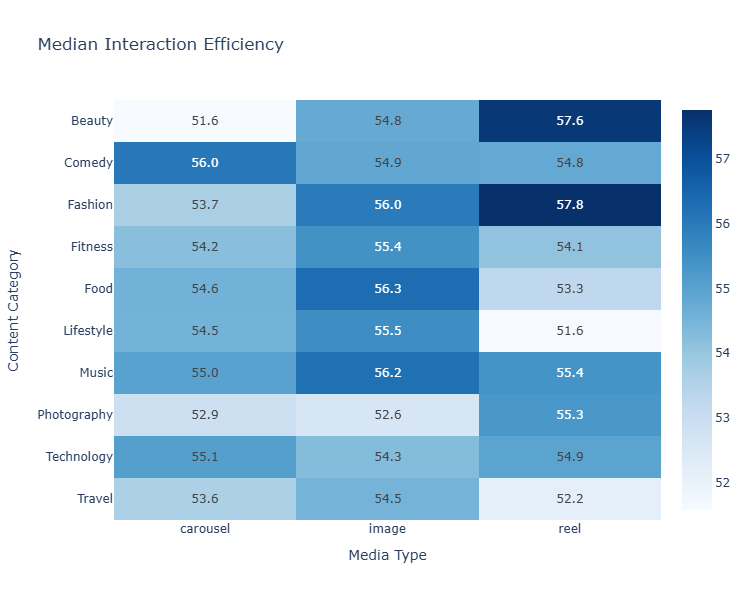

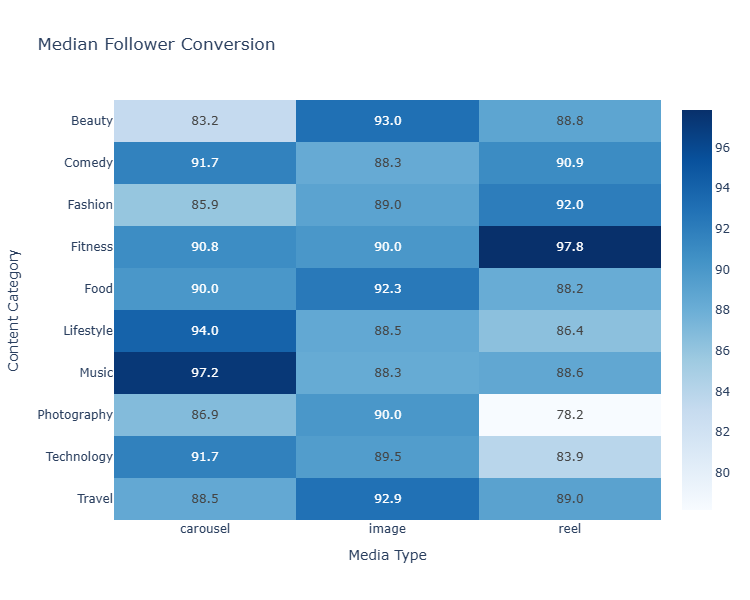

In [9]:
import plotly.express as px


metric_info = {

    "median_reach_rate": {
        "title": "Median Reach Rate",
        "format": ".3f"
    },

    "median_interaction_efficiency": {
        "title": "Median Interaction Efficiency",
        "format": ".1f"
    },

    "median_follower_conversion": {
        "title": "Median Follower Conversion",
        "format": ".1f"
    }
}


for metric, info in metric_info.items():

    heatmap_data = (
        format_performance
        .pivot(
            index="content_category",
            columns="media_type",
            values=metric
        )
    )

    fig = px.imshow(
        heatmap_data,
        text_auto=info["format"],
        aspect="auto",
        title=info["title"],
        color_continuous_scale="Blues"
    )

    fig.update_layout(
        xaxis_title="Media Type",
        yaxis_title="Content Category",
        template="plotly_white",
        height=600,
        width=750
    )

    fig.show(renderer="png")

## account-adjusted analysis

避免擁有極端值的帳號，將account拉出來討論

In [10]:
account_performance = (
    analysis_df
    .groupby(
        [
            "account_id",
            "content_category",
            "media_type"
        ],
        observed=True
    )
    .agg(
        n_posts=(
            "post_id",
            "count"
        ),

        median_reach_rate=(
            "reach_rate",
            "median"
        ),

        median_interaction_efficiency=(
            "interactions_per_1000_reach",
            "median"
        ),

        median_follower_conversion=(
            "followers_per_1000_reach",
            "median"
        )
    )
    .reset_index()
)

只留下三種media type都有的，以及貼文數>5的

In [11]:
account_performance["media_type"].nunique() == 3

MIN_POSTS = 5

valid_account_groups = (
    account_performance
    .groupby(
        [
            "account_id",
            "content_category"
        ],
        observed=True
    )
    .filter(
        lambda x:
        (
            x["media_type"].nunique() == 3
        )
        and
        (
            x["n_posts"].min() >= MIN_POSTS
        )
    )
    .copy()
)

每個 account × topic 內建立 baseline

baseline 的計算方法: 在每個account中，對三種media_type各自取median，再對這三個median取mean (平均權重)

In [12]:
account_baseline = (
    valid_account_groups
    .groupby(
        [
            "account_id",
            "content_category"
        ],
        observed=True
    )
    .agg(
        baseline_reach_rate=(
            "median_reach_rate",
            "mean"
        ),

        baseline_interaction_efficiency=(
            "median_interaction_efficiency",
            "mean"
        ),

        baseline_follower_conversion=(
            "median_follower_conversion",
            "mean"
        )
    )
    .reset_index()
)

merge

In [13]:
account_lift = (
    valid_account_groups
    .merge(
        account_baseline,
        on=[
            "account_id",
            "content_category"
        ],
        how="left",
        validate="many_to_one"
    )
)

lift : 看三種median_type跟baseline對比下的表現

In [14]:
account_lift["reach_lift_pct"] = (
    (
        account_lift["median_reach_rate"]
        / account_lift["baseline_reach_rate"]
    )
    - 1
) * 100


account_lift["interaction_lift_pct"] = (
    (
        account_lift["median_interaction_efficiency"]
        / account_lift[
            "baseline_interaction_efficiency"
        ]
    )
    - 1
) * 100


account_lift["follower_lift_pct"] = (
    (
        account_lift["median_follower_conversion"]
        / account_lift[
            "baseline_follower_conversion"
        ]
    )
    - 1
) * 100

整合所有account: 對20個account的lift取median

In [15]:
account_adjusted_lift = (
    account_lift
    .groupby(
        [
            "content_category",
            "media_type"
        ],
        observed=True
    )
    .agg(
        n_accounts=(
            "account_id",
            "nunique"
        ),

        median_reach_lift=(
            "reach_lift_pct",
            "median"
        ),

        median_interaction_lift=(
            "interaction_lift_pct",
            "median"
        ),

        median_follower_lift=(
            "follower_lift_pct",
            "median"
        )
    )
    .reset_index()
)

account_adjusted_lift

,content_category,media_type,n_accounts,median_reach_lift,median_interaction_lift,median_follower_lift
0,Beauty,carousel,20,5.396111,-4.144856,-5.758508
1,Beauty,image,20,-1.799774,-1.793869,5.706256
2,Beauty,reel,20,-3.182120,7.561784,-7.669838
3,Comedy,carousel,20,-2.653621,1.253625,4.900473
4,Comedy,image,20,0.555965,-2.483825,-3.681400
5,Comedy,reel,20,2.437694,0.276335,-1.056402
6,Fashion,carousel,20,0.905855,-2.990552,-0.187841
7,Fashion,image,20,2.962472,-1.362746,1.517967
8,Fashion,reel,20,-2.881448,6.011280,0.851590
9,Fitness,carousel,20,-0.358006,-3.749389,1.973887


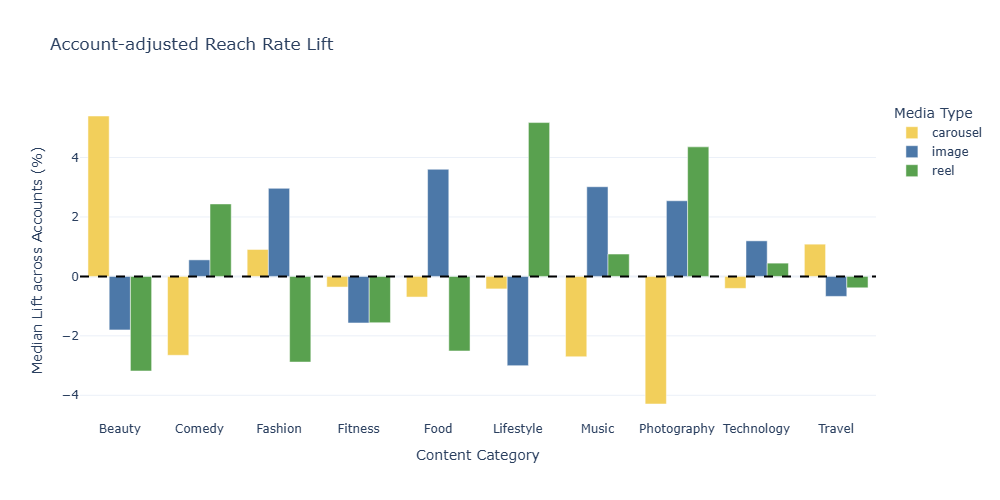

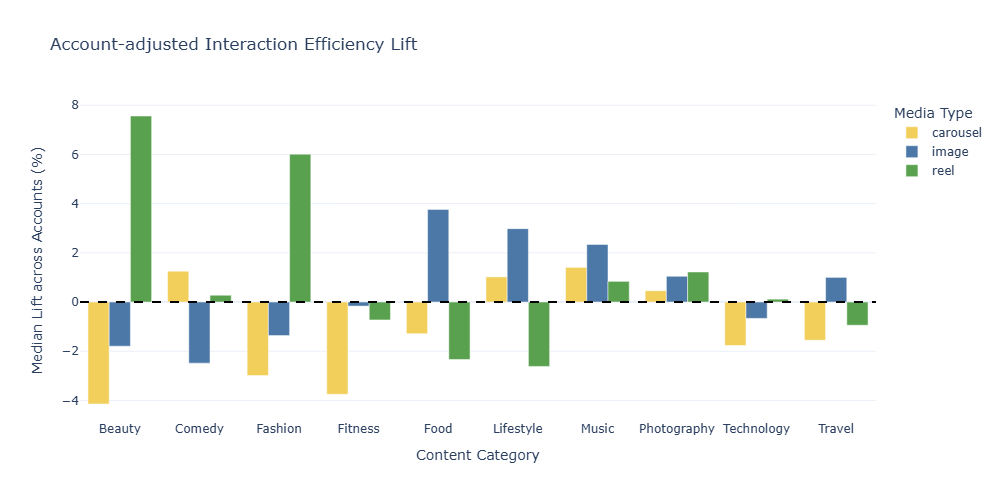

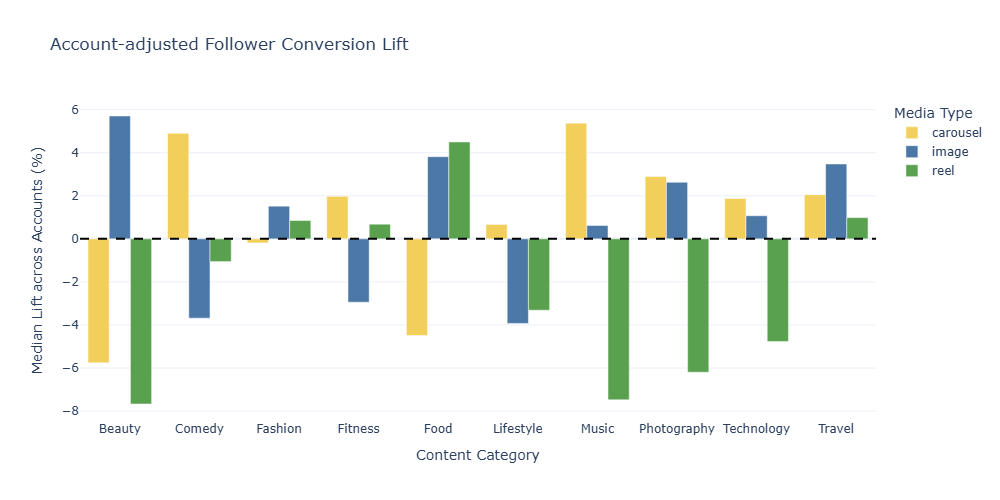

In [16]:
lift_metrics = {

    "median_reach_lift": {
        "title":
        "Account-adjusted Reach Rate Lift",
        "y_title":
        "Median Lift across Accounts (%)"
    },

    "median_interaction_lift": {
        "title":
        "Account-adjusted Interaction Efficiency Lift",
        "y_title":
        "Median Lift across Accounts (%)"
    },

    "median_follower_lift": {
        "title":
        "Account-adjusted Follower Conversion Lift",
        "y_title":
        "Median Lift across Accounts (%)"
    }
}


for metric, info in lift_metrics.items():

    fig = px.bar(
        account_adjusted_lift,
        x="content_category",
        y=metric,
        color="media_type",
        barmode="group",
        color_discrete_map=media_colors,
        title=info["title"],
        hover_data=["n_accounts"]
    )

    fig.add_hline(
        y=0,
        line_dash="dash",
        line_color="black"
    )

    fig.update_layout(
        xaxis_title="Content Category",
        yaxis_title=info["y_title"],
        legend_title="Media Type",
        template="plotly_white",
        height=500,
        width=1000
    )

    fig.show(renderer="png")

Win Rate: 在多少 account 裡，它真的排名第一 (cross-account consistency)

Win Rate 在 content_catogory 的三種 media type 中相加會等於100

In [17]:
def calculate_win_rate(
    data,
    metric,
    metric_name
):

    temp = data[
        [
            "account_id",
            "content_category",
            "media_type",
            metric
        ]
    ].copy()


    # Maximum value within each account × topic
    temp["group_max"] = (
        temp
        .groupby(
            [
                "account_id",
                "content_category"
            ],
            observed=True
        )[metric]
        .transform("max")
    )


    # Identify all tied winners
    temp["is_winner"] = (
        temp[metric]
        == temp["group_max"]
    )


    # Number of tied winners
    temp["n_tied_winners"] = (
        temp
        .groupby(
            [
                "account_id",
                "content_category"
            ],
            observed=True
        )["is_winner"]
        .transform("sum")
    )


    # Fractional win
    temp["win_weight"] = (
        temp["is_winner"]
        / temp["n_tied_winners"]
    )


    # Number of comparable accounts
    denominator = (
        temp[
            [
                "account_id",
                "content_category"
            ]
        ]
        .drop_duplicates()
        .groupby(
            "content_category",
            observed=True
        )
        .size()
        .reset_index(
            name="n_comparable_accounts"
        )
    )


    win_result = (
        temp
        .groupby(
            [
                "content_category",
                "media_type"
            ],
            observed=True
        )["win_weight"]
        .sum()
        .reset_index(
            name="weighted_wins"
        )
    )


    result = win_result.merge(
        denominator,
        on="content_category",
        how="left"
    )


    result["win_rate_pct"] = (
        result["weighted_wins"]
        / result["n_comparable_accounts"]
        * 100
    )


    result["metric"] = metric_name

    return result

In [18]:
reach_win_rate = calculate_win_rate(
    valid_account_groups,
    "median_reach_rate",
    "Reach Rate"
)

interaction_win_rate = calculate_win_rate(
    valid_account_groups,
    "median_interaction_efficiency",
    "Interaction Efficiency"
)

follower_win_rate = calculate_win_rate(
    valid_account_groups,
    "median_follower_conversion",
    "Follower Conversion"
)

win_rate_df = pd.concat(
    [
        reach_win_rate,
        interaction_win_rate,
        follower_win_rate
    ],
    ignore_index=True
)

In [19]:
win_rate_df

,content_category,media_type,weighted_wins,n_comparable_accounts,win_rate_pct,metric
0,Beauty,carousel,9.0,20,45.0,Reach Rate
1,Beauty,image,5.0,20,25.0,Reach Rate
2,Beauty,reel,6.0,20,30.0,Reach Rate
3,Comedy,carousel,6.0,20,30.0,Reach Rate
4,Comedy,image,4.0,20,20.0,Reach Rate
...,...,...,...,...,...,...
85,Technology,image,8.0,20,40.0,Follower Conversion
86,Technology,reel,5.0,20,25.0,Follower Conversion
87,Travel,carousel,5.0,20,25.0,Follower Conversion
88,Travel,image,8.0,20,40.0,Follower Conversion


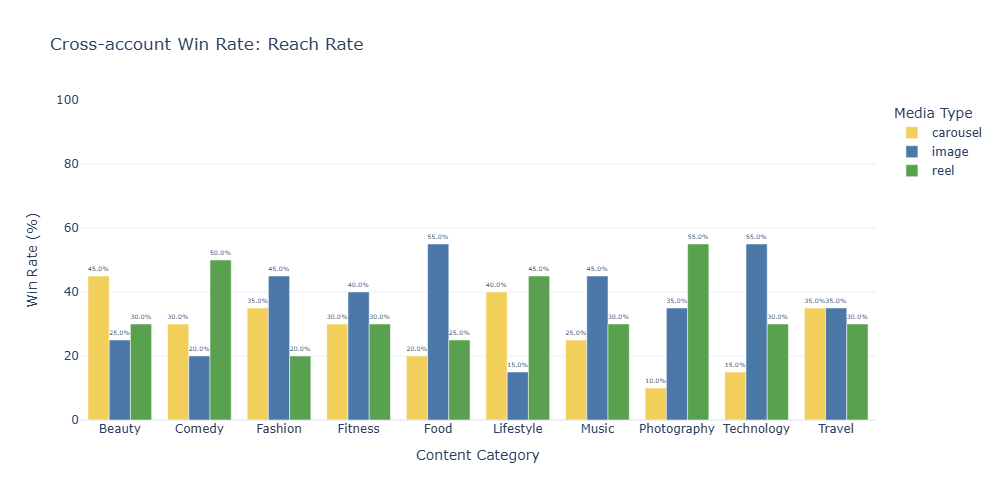

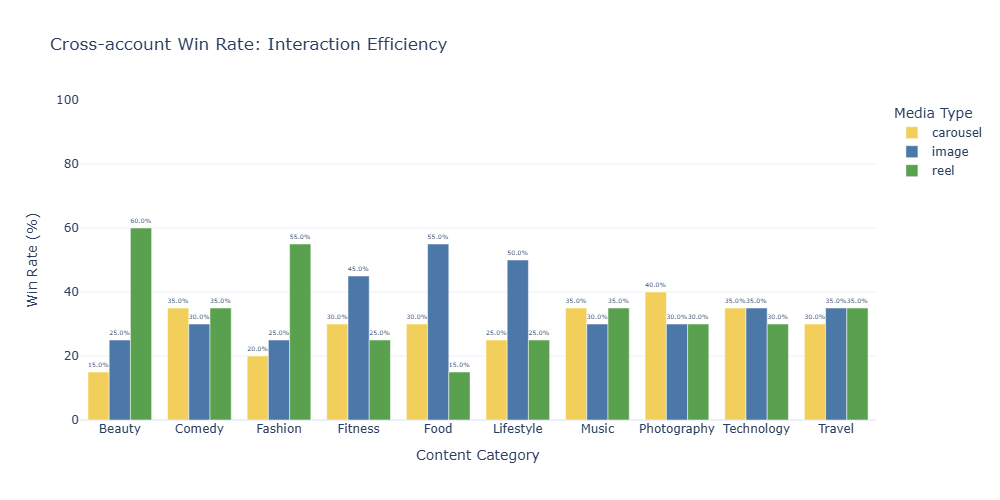

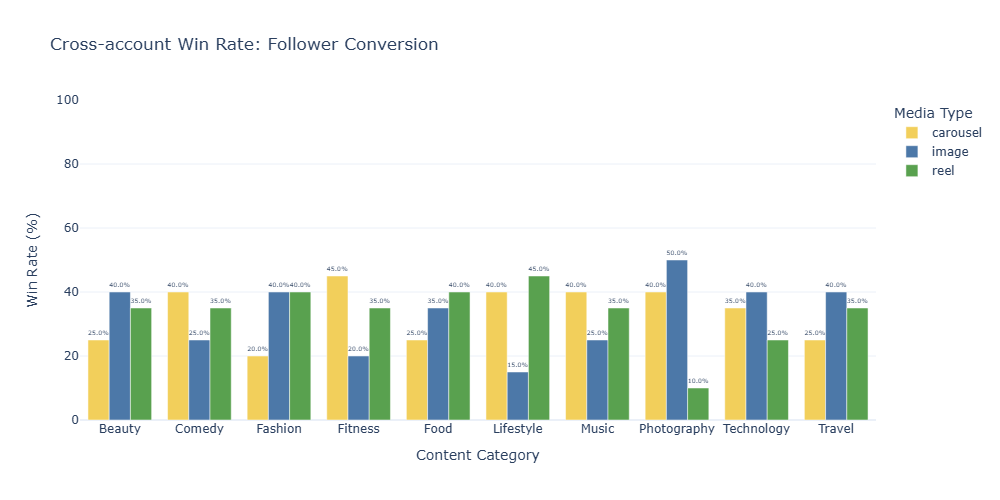

In [20]:
import plotly.express as px

media_colors = {
    "image": "#4C78A8",
    "carousel": "#F2CF5B",
    "reel": "#59A14F"
}

for metric_name in win_rate_df["metric"].unique():

    plot_data = win_rate_df[
        win_rate_df["metric"] == metric_name
    ].copy()

    fig = px.bar(
        plot_data,
        x="content_category",
        y="win_rate_pct",
        color="media_type",
        barmode="group",
        color_discrete_map=media_colors,
        text="win_rate_pct",
        title=f"Cross-account Win Rate: {metric_name}"
    )

    fig.update_traces(
        texttemplate="%{text:.1f}%",
        textposition="outside"
    )

    fig.update_layout(
        xaxis_title="Content Category",
        yaxis_title="Win Rate (%)",
        yaxis=dict(range=[0, 100]),
        legend_title="Media Type",
        template="plotly_white",
        height=500,
        width=1000
    )

    fig.show(renderer="png")

In [21]:
# Find the highest win rate
summary_winner = (
    win_rate_df
    .loc[
        win_rate_df
        .groupby(
            ["content_category", "metric"]
        )["win_rate_pct"]
        .idxmax()
    ]
    .copy()
)


In [22]:
summary_winner["winner"] = (
    summary_winner["media_type"].str.title()
    + " ("
    + summary_winner["win_rate_pct"].round(1).astype(str)
    + "%)"
)

In [24]:
summary_table = (
    summary_winner
    .pivot(
        index="content_category",
        columns="metric",
        values="winner"
    )
    .reset_index()
)

summary_table = summary_table[
    [
        "content_category",
        "Reach Rate",
        "Interaction Efficiency",
        "Follower Conversion"
    ]
]

summary_table = summary_table.rename(
    columns={
        "content_category": "Content Category",
        "Reach Rate": "Reach Winner",
        "Interaction Efficiency": "Interaction Winner",
        "Follower Conversion": "Follower Growth Winner"
    }
)

summary_table

metric,Content Category,Reach Winner,Interaction Winner,Follower Growth Winner
0,Beauty,Carousel (45.0%),Reel (60.0%),Image (40.0%)
1,Comedy,Reel (50.0%),Carousel (35.0%),Carousel (40.0%)
2,Fashion,Image (45.0%),Reel (55.0%),Image (40.0%)
3,Fitness,Image (40.0%),Image (45.0%),Carousel (45.0%)
4,Food,Image (55.0%),Image (55.0%),Reel (40.0%)
5,Lifestyle,Reel (45.0%),Image (50.0%),Reel (45.0%)
6,Music,Image (45.0%),Carousel (35.0%),Carousel (40.0%)
7,Photography,Reel (55.0%),Carousel (40.0%),Image (50.0%)
8,Technology,Image (55.0%),Carousel (35.0%),Image (40.0%)
9,Travel,Carousel (35.0%),Image (35.0%),Image (40.0%)
